# Model Validation — A Simpler Beginner Notebook

**One question:** will a model work well on new examples?

We use one real dataset, short Python examples, and **Seaborn** charts. Run from top to bottom in Google Colab: **File → Upload notebook**, then **Runtime → Run all**. A CPU is enough. The dataset is bundled with scikit-learn, so no data download is needed.

Our route:
1. **Data splits:** separate learning, choosing, and final checking.
2. **Overfitting and underfitting:** compare a constant prediction, a straight line, and a flexible curve.
3. **Bias and variance:** see how predictions change with different training patients.
4. **Cross-validation:** repeat evaluation across several folds, then test once.

The decision-tree examples are a short optional extension. Every modeling example uses the same pattern: **create → fit → predict → evaluate**.

**Chart colors:** training = teal; validation = orange; final test = purple. These are static Seaborn charts. Matplotlib supplies the axes and displays them.

## Setup
NumPy works with numbers, pandas holds tables, Seaborn draws charts, and scikit-learn provides datasets and models. You can leave these imports unchanged.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

SEED = 42
TRAIN, VAL, TEST = '#087e8b', '#bc4b12', '#7255b8'
sns.set_theme(style='whitegrid', font_scale=1.05)

## Meet the real data
The diabetes dataset contains baseline measurements for 442 patients and a numerical measure of progression one year later. We predict that score, **not a yes/no diagnosis**.

To keep every chart easy to follow, we use just one input: **BMI**. Other useful inputs are deliberately omitted in this teaching example.

`data` is a table with two columns: the input `bmi` and the answer `target`. Keeping them together makes splitting and sampling simpler. `scaled=False` loads the raw features without learning scaling from the whole dataset.

In [2]:
diabetes = load_diabetes(as_frame=True, scaled=False)
data = diabetes.data.copy()
data.columns = data.columns.str.lower()
data = data[['bmi']]
data['target'] = diabetes.target

print('Patient records:', len(data))
print(data.head().round(1).to_string(index=False))

Patient records: 442
 bmi  target
32.1   151.0
21.6    75.0
30.5   141.0
25.3   206.0
23.0   135.0


# 1. Data splits

Think of a textbook, a practice exam, and a sealed final exam.

| Set | Its job |
|---|---|
| Training | Teach the model a rule |
| Validation | Compare models and choose settings |
| Test | Audit the final choice once |

First reserve 20% for testing. Split the remaining 80% into training and validation. Taking 25% of that remainder gives approximately **60% training, 20% validation, 20% test**, rounded to whole patients.

The features and targets stay together because we split the whole two-column table directly.

In [3]:
development, test = train_test_split(
    data, test_size=0.20, random_state=SEED
)
train, validation = train_test_split(
    development, test_size=0.25, random_state=SEED
)

print('Training patients:', len(train))
print('Validation patients:', len(validation))
print('Test patients:', len(test))

Training patients: 264
Validation patients: 89
Test patients: 89


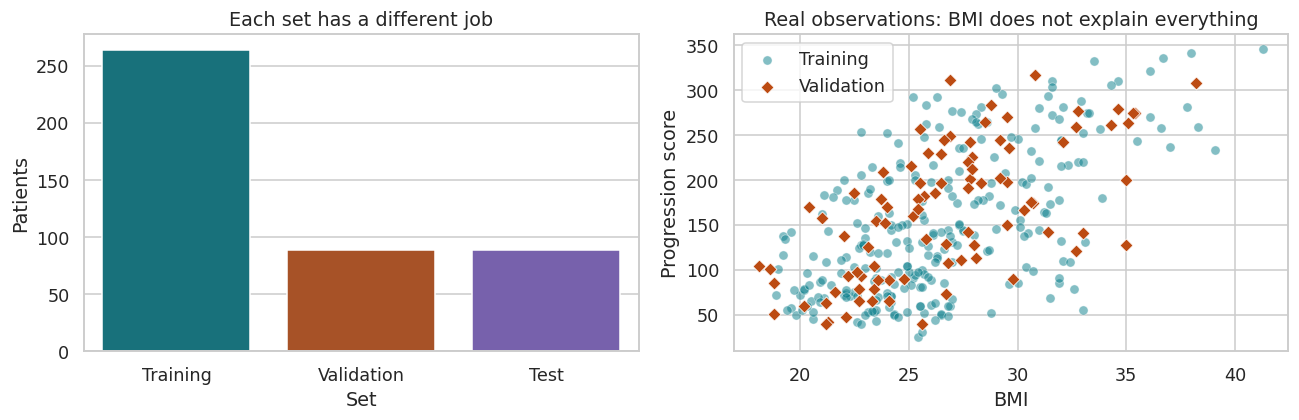

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_sizes = pd.DataFrame({'Set': ['Training', 'Validation', 'Test'],
                            'Patients': [len(train), len(validation), len(test)]})
sns.barplot(data=split_sizes, x='Set', y='Patients', hue='Set',
            palette=[TRAIN, VAL, TEST], legend=False, ax=axes[0])
axes[0].set(title='Each set has a different job', ylabel='Patients')
sns.scatterplot(data=train, x='bmi', y='target', color=TRAIN,
                label='Training', alpha=0.5, ax=axes[1])
sns.scatterplot(data=validation, x='bmi', y='target', color=VAL,
                marker='D', label='Validation', ax=axes[1])
axes[1].set(title='Real observations: BMI does not explain everything',
            xlabel='BMI', ylabel='Progression score')
plt.tight_layout()
plt.show()

**What to notice:** patients with similar BMI can have different outcomes. A model should learn useful patterns rather than explain every individual difference using BMI alone. Test targets are not plotted during development.

**Variants:** random splitting suits independent examples. Use stratification to preserve class proportions in classification, group splitting for repeated records from the same person, and a time split for forecasting. Choose a split that resembles future use.

**Check:** can you keep choosing models by their test score?
<details><summary>Answer</summary>
No. That makes the test set part of selection. Use validation or cross-validation to choose, then test once.
</details>

# 2. Overfitting and underfitting

Start with **ordinary linear regression**: a straight-line relationship between BMI and progression score.

- `.fit(...)` learns the rule from training patients.
- `.predict(...)` applies it to patients whose answers were not used in fitting.
- **MSE** averages squared prediction mistakes. Lower is better; large mistakes count more.

Why double brackets in `[['bmi']]`? scikit-learn expects a table of input columns, even when there is only one. `['target']` selects the answer column.

In [5]:
line = LinearRegression()
line.fit(train[['bmi']], train['target'])
predictions = line.predict(validation[['bmi']])
error = mean_squared_error(validation['target'], predictions)

print('Straight-line validation MSE:', round(error, 1))

Straight-line validation MSE: 3430.1


## Compare three prediction rules

| Model | What it does | What to look for |
|---|---|---|
| Mean only | Predicts the training average for everyone | Can miss the relationship entirely |
| Straight line | Uses one line relating BMI to the target | May capture a useful broad pattern |
| Flexible curve | Uses powers of BMI to allow bends | May chase sample-specific details |

The flexible curve is **polynomial regression**. It still uses `LinearRegression`, but receives transformed inputs. Its **degree** controls how much it can bend. A pipeline applies scaling, creates polynomial features, then fits regression. All learned steps use training patients only.

You do not need to memorize pipeline syntax: focus on changing `degree` and comparing errors.

In [6]:
curved_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=8, include_bias=False),
    LinearRegression()
)
models = {
    'Mean only': DummyRegressor(strategy='mean'),
    'Straight line': LinearRegression(),
    'Flexible curve': curved_model
}

results = []
for name, model in models.items():
    model.fit(train[['bmi']], train['target'])
    train_predictions = model.predict(train[['bmi']])
    val_predictions = model.predict(validation[['bmi']])
    results.append({
        'Model': name,
        'Training MSE': mean_squared_error(train['target'], train_predictions),
        'Validation MSE': mean_squared_error(validation['target'], val_predictions)
    })
results = pd.DataFrame(results)
print(results.round(1).to_string(index=False))

         Model  Training MSE  Validation MSE
     Mean only        6216.7          5721.3
 Straight line        4012.7          3430.1
Flexible curve        3846.4          3825.5


The next cell just draws the predictions. `grid` is a list of BMI positions where we ask the fitted models for predictions; it does **not** create new training patients or targets.

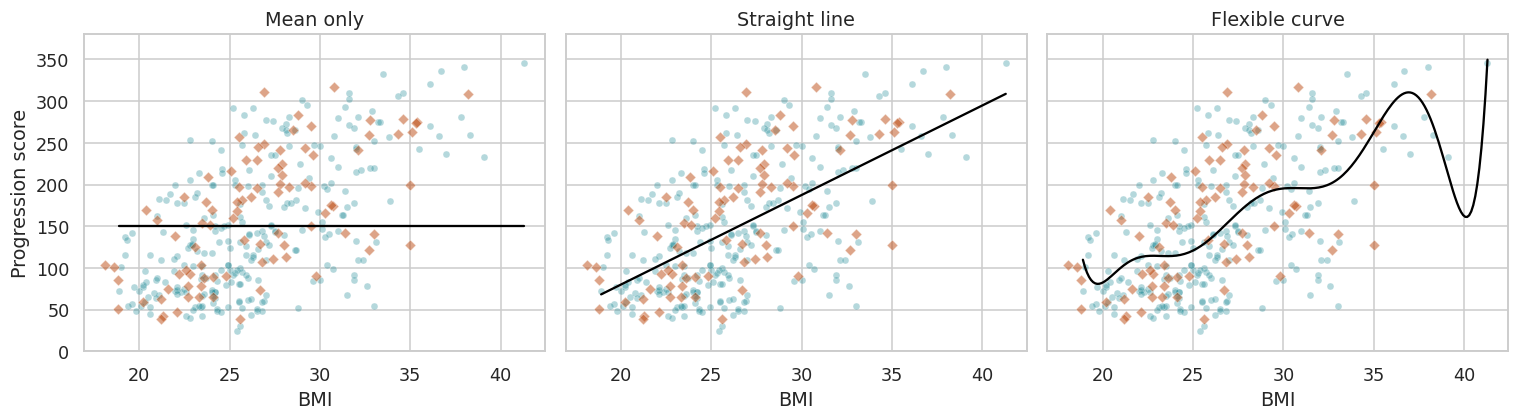

In [7]:
grid = pd.DataFrame({'bmi': np.linspace(train['bmi'].min(), train['bmi'].max(), 200)})
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    sns.scatterplot(data=train, x='bmi', y='target', color=TRAIN,
                    alpha=0.3, s=20, ax=ax)
    sns.scatterplot(data=validation, x='bmi', y='target', color=VAL,
                    marker='D', alpha=0.5, s=25, ax=ax)
    sns.lineplot(x=grid['bmi'], y=model.predict(grid), color='black', ax=ax)
    ax.set(title=name, xlabel='BMI', ylabel='Progression score', ylim=(0, 380))
plt.tight_layout()
plt.show()

**Read the results:**
- A rigid rule with high training and validation errors may be **underfitting**.
- A flexible rule with lower training error but worse validation error may be **overfitting**.
- Prefer useful validation performance, not a perfect training fit.

A straight line is not automatically underfitting. It may be a good balance for these observations. Validation error can also be lower than training error on one split because the sets contain different patients.

**Try it:** change the curve's `degree` from 8 to 3, then rerun its comparison cells. Does validation improve? The chart initially hides predictions outside 0–380; MSE still includes every prediction.

## Optional: decision-tree steps and leaf size
A decision tree sorts patients into final groups called **leaves**. Each leaf predicts its training patients' average outcome.

A flat step covers one BMI group. A jump means crossing into another group with a different prediction.

`min_samples_leaf=1` allows tiny groups. `min_samples_leaf=40` requires **at least 40 training rows** per final group. Larger groups often make predictions steadier, but can miss useful detail. The setting is a minimum, not an exact group size, and it does not count validation rows.

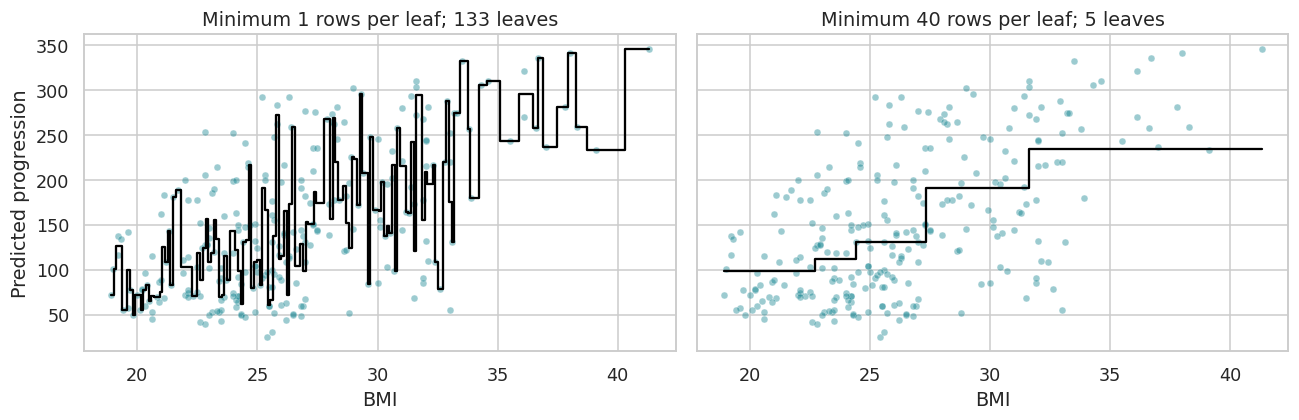

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
trees = {}
for ax, minimum in zip(axes, [1, 40]):
    tree = DecisionTreeRegressor(min_samples_leaf=minimum, random_state=SEED)
    tree.fit(train[['bmi']], train['target'])
    trees[minimum] = tree
    sns.scatterplot(data=train, x='bmi', y='target', color=TRAIN,
                    alpha=0.4, s=20, ax=ax)
    sns.lineplot(x=grid['bmi'], y=tree.predict(grid),
                 color='black', drawstyle='steps-post', ax=ax)
    ax.set(title=f'Minimum {minimum} rows per leaf; {tree.get_n_leaves()} leaves',
           xlabel='BMI', ylabel='Predicted progression')
plt.tight_layout()
plt.show()

Here we open the leaves and count the training patients. **One bar is one actual leaf.** Every bar must reach the dashed minimum line. Leaves are ordered by their internal tree IDs.

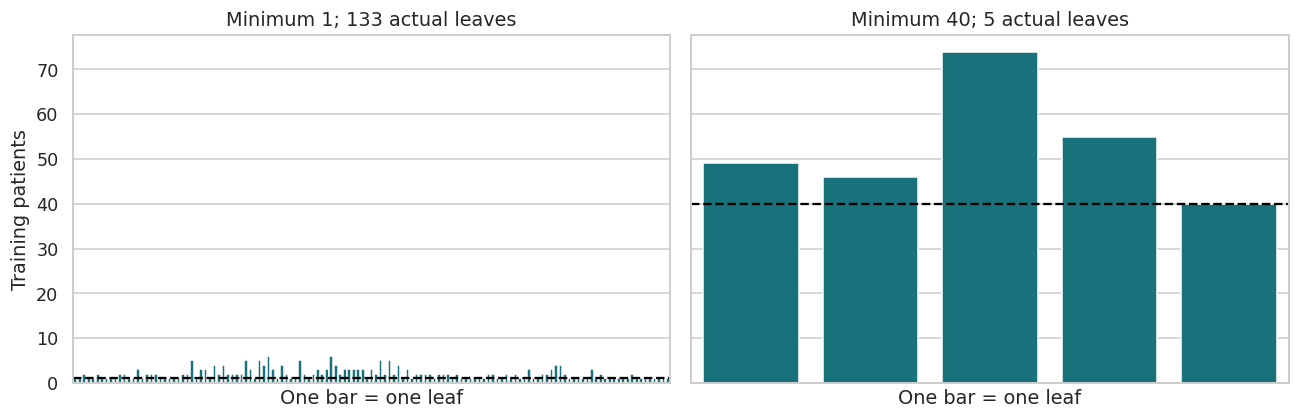

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, minimum in zip(axes, [1, 40]):
    leaf_ids = trees[minimum].apply(train[['bmi']])
    leaf_names, counts = np.unique(leaf_ids, return_counts=True)
    sns.barplot(x=np.arange(1, len(counts) + 1), y=counts, color=TRAIN, ax=ax)
    ax.axhline(minimum, color='black', linestyle='--')
    ax.set(title=f'Minimum {minimum}; {len(counts)} actual leaves',
           xlabel='One bar = one leaf', ylabel='Training patients')
    ax.set_xticks([])  # Hide crowded leaf numbers.
plt.tight_layout()
plt.show()

# 3. Bias–variance tradeoff

**Bias:** a rule systematically misses useful structure. Example: ignoring BMI and predicting one number for everyone may be too rigid.

**Variance:** a learned rule changes when different training examples are selected. Example: a flexible curve may bend differently for each new group of patients.

## First, just watch the straight lines
We repeatedly select **80 real training patients** and fit a new straight line. This simpler experiment samples **without replacement within each group**. Groups can overlap with one another. We do not create patient measurements or add artificial noise.

Each line uses the same algorithm and settings. Only its training patients change. The validation and test sets stay out of fitting.

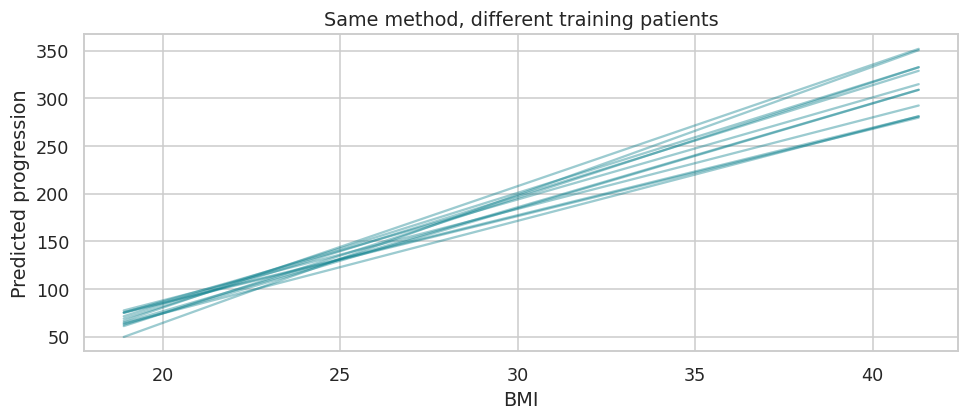

In [10]:
linear_predictions = []
for seed in range(12):
    sample = train.sample(n=80, random_state=seed)
    model = LinearRegression()
    model.fit(sample[['bmi']], sample['target'])
    linear_predictions.append(model.predict(grid))

fig, ax = plt.subplots(figsize=(9, 4))
for predictions in linear_predictions:
    sns.lineplot(x=grid['bmi'], y=predictions, color=TRAIN, alpha=0.4, ax=ax)
ax.set(title='Same method, different training patients',
       xlabel='BMI', ylabel='Predicted progression')
plt.tight_layout()
plt.show()

**Ask the class:** do the lines stay close together, or separate substantially at the same BMI?

Close predictions suggest stability. Wider separation suggests sensitivity to the training sample. Compare at the **same BMI**, not at different points along a single line.

## Now repeat with a flexible curve
Keep the same groups of 80 patients. Change only the model: use a degree-8 polynomial regression instead of a straight line. `clone` makes a fresh, unfitted copy of the curve model from Section 2.

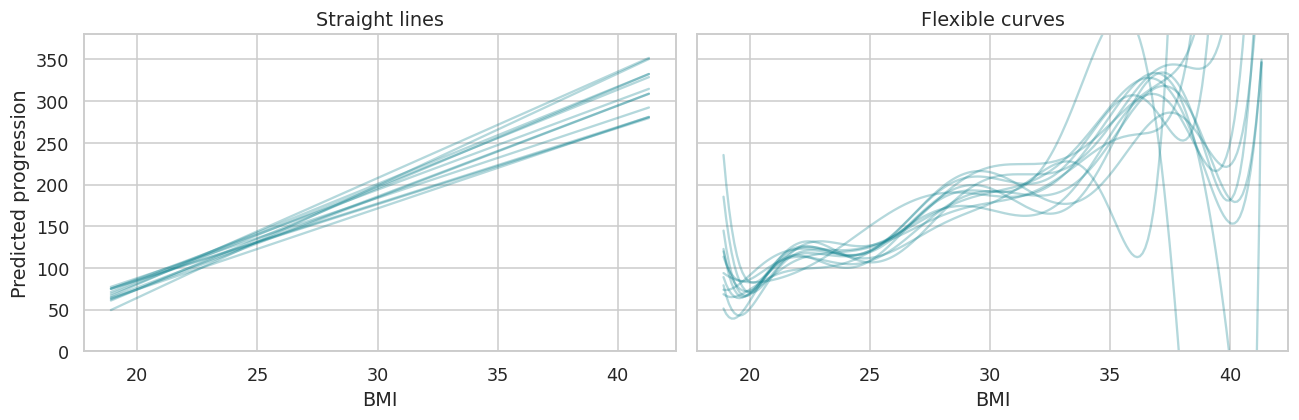

In [11]:
curve_predictions = []
for seed in range(12):
    sample = train.sample(n=80, random_state=seed)
    model = clone(curved_model)
    model.fit(sample[['bmi']], sample['target'])
    curve_predictions.append(model.predict(grid))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, predictions_list, title in zip(
    axes, [linear_predictions, curve_predictions], ['Straight lines', 'Flexible curves']
):
    for predictions in predictions_list:
        sns.lineplot(x=grid['bmi'], y=predictions, color=TRAIN, alpha=0.3, ax=ax)
    ax.set(title=title, xlabel='BMI', ylabel='Predicted progression', ylim=(0, 380))
plt.tight_layout()
plt.show()

**The connection:** extra flexibility may improve the training fit but make predictions more sensitive to which patients were selected. That is the variance side of the tradeoff. Edge behavior can be especially unstable; the shared vertical range may hide extreme curves.

Stability alone is not enough. A constant rule can be stable and still miss useful patterns. Use validation error alongside these plots.

| What you observe | What to try |
|---|---|
| Training and validation errors both high | Better inputs or a more expressive model |
| Training low, validation much higher | A simpler model, larger tree leaves, or relevant additional data |
| Predictions change a lot across samples | Less flexibility, more representative data, or averaging models |

**Important limit:** we do not know the true underlying relationship in this real dataset. We can demonstrate sample sensitivity, but cannot directly measure true bias or a known noise floor.

**Try it:** use 150 patients instead of 80 in **both** sampling cells. Do the predictions become steadier? The available rows are still one finite dataset, not newly collected patients.

**Check:** does a very stable model have to be accurate?
<details><summary>Answer</summary>
No. It can consistently miss the pattern. We need held-out error as well as stability.
</details>

# 4. Cross-validation

A single validation set may be unusually easy or difficult. **K-fold cross-validation** repeats the rehearsal:
1. Divide development data into K folds.
2. Fit a fresh model on K−1 folds.
3. Score it on the remaining fold.
4. Rotate until every fold has been held out once.

In five-fold CV, each development patient is validated once and trained on in the other four runs. The final test patients remain excluded.

The chart uses teal for training and orange for validation. Each row is one run.

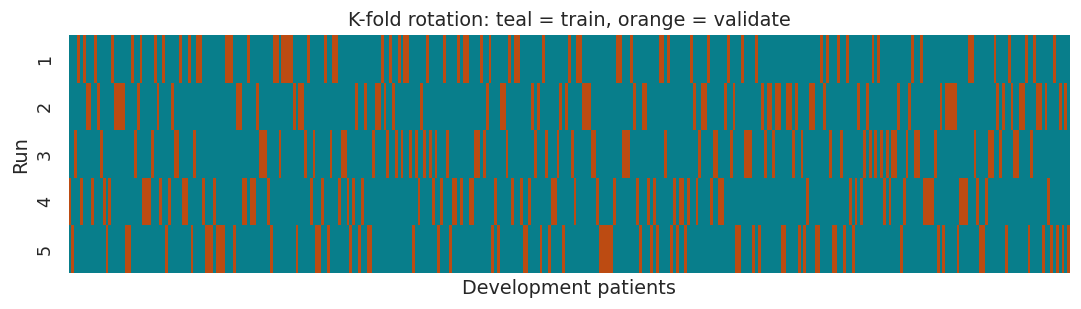

In [12]:
K = 5
kfold = KFold(n_splits=K, shuffle=True, random_state=SEED)
folds = list(kfold.split(development))
roles = np.zeros((K, len(development)))
for run, (train_positions, val_positions) in enumerate(folds):
    roles[run, val_positions] = 1

fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(roles, cmap=[TRAIN, VAL], cbar=False, xticklabels=False,
            yticklabels=range(1, K + 1), ax=ax)
ax.set(title='K-fold rotation: teal = train, orange = validate',
       xlabel='Development patients', ylabel='Run')
plt.tight_layout()
plt.show()

## Fit, predict, evaluate — repeated
First choose a candidate using the validation comparisons from Section 2. Then rehearse CV with that candidate.

`.iloc` selects table rows by their **positions** supplied by KFold. It is not a model operation. `clone` creates a fresh model for every run.

We use a manual loop so every score stays an ordinary positive MSE: there is no negative-scoring convention to learn here. We combine the earlier training and validation rows as development data. Because that data already influenced candidate selection, this CV result is a teaching rehearsal; the untouched test remains the final audit.

In [13]:
best_row = results.sort_values('Validation MSE').iloc[0]
best_name = best_row['Model']
print('Candidate selected using validation:', best_name)

fold_errors = []
for train_positions, val_positions in folds:
    fold_train = development.iloc[train_positions]
    fold_val = development.iloc[val_positions]
    model = clone(models[best_name])
    model.fit(fold_train[['bmi']], fold_train['target'])
    predictions = model.predict(fold_val[['bmi']])
    error = mean_squared_error(fold_val['target'], predictions)
    fold_errors.append(error)

print('Fold MSEs:', np.round(fold_errors, 1))
print('Mean fold MSE:', round(np.mean(fold_errors), 1))

Candidate selected using validation: Straight line
Fold MSEs: [3734.6 3849.3 3651.8 4104.6 4205.4]
Mean fold MSE: 3909.2


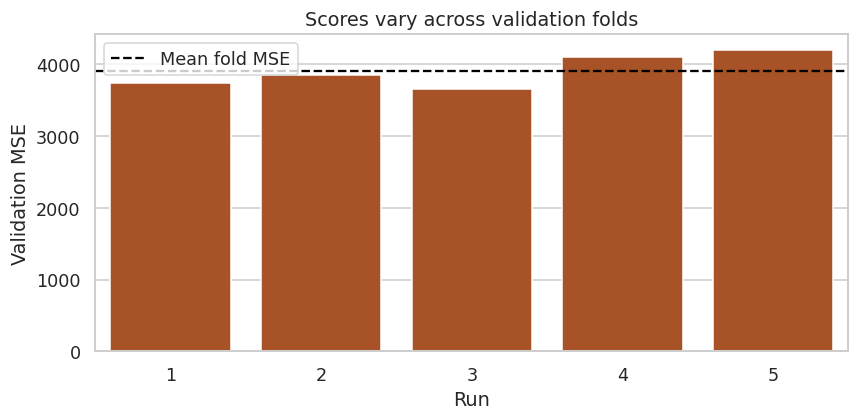

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=np.arange(1, K + 1), y=fold_errors, color=VAL, ax=ax)
ax.axhline(np.mean(fold_errors), color='black', linestyle='--', label='Mean fold MSE')
ax.set(title='Scores vary across validation folds', xlabel='Run', ylabel='Validation MSE')
ax.legend()
plt.tight_layout()
plt.show()

**What to notice:** fold scores differ because different patients are held out. Their mean summarizes the repeated evaluation. Score variation is not the same as prediction variance in Section 3, and it is not a confidence interval.

To compare several candidates using CV, give each candidate the same folds and metric, then compare their mean errors. In a standard CV workflow, CV replaces the single validation split for selection; the test set still stays separate.

**Variants:** use stratified folds for independent classification examples, grouped folds for related records, and forward-in-time splits for forecasting. More folds require more model fits; five is a useful starting example, not a universal rule.

## Final audit
Refit the chosen model on all development patients, then reveal the test targets once. Do not change settings based on this score and still call it an independent test.

**RMSE** is the square root of MSE, so it is expressed in progression-score units.

In [15]:
final_model = clone(models[best_name])
final_model.fit(development[['bmi']], development['target'])
test_predictions = final_model.predict(test[['bmi']])
test_mse = mean_squared_error(test['target'], test_predictions)
print('Final model:', best_name)
print('Test MSE:', round(test_mse, 1))
print('Test RMSE:', round(np.sqrt(test_mse), 1))

Final model: Straight line
Test MSE: 4061.8
Test RMSE: 63.7


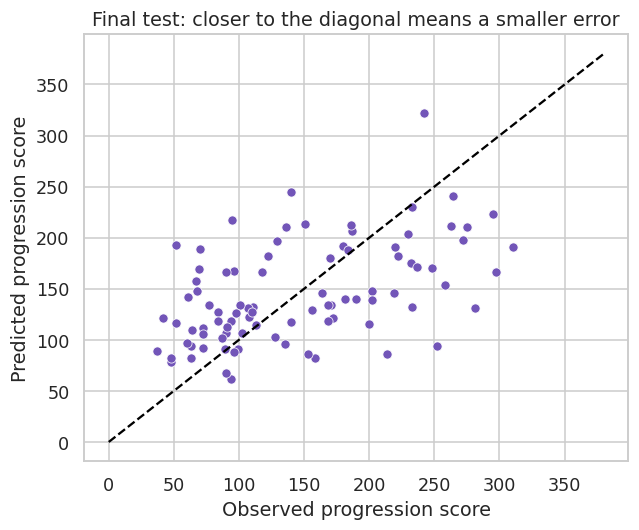

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(x=test['target'], y=test_predictions, color=TEST, ax=ax)
sns.lineplot(x=[0, 380], y=[0, 380], color='black', linestyle='--', ax=ax)
ax.set(title='Final test: closer to the diagonal means a smaller error',
       xlabel='Observed progression score', ylabel='Predicted progression score')
plt.tight_layout()
plt.show()

## Keep these four ideas connected

**Split fairly → compare flexibility → check sample sensitivity → repeat validation → audit on test.**

Before trusting a result:
- Use only information available at prediction time.
- Keep related records and future information out of the wrong split.
- Fit learned preprocessing inside training only, including each CV training fold.
- Compare with the same metric and appropriate splits.
- Reserve the final test set for the last evaluation.

### Final check
1. Does a low training error prove generalization?
2. What does the spread between fitted lines demonstrate?
3. How many models are fitted for one five-fold CV candidate?
4. What do we do after choosing the final approach?

<details><summary>Answers</summary>

1. No; inspect held-out performance.
2. Sensitivity to which training patients were selected.
3. Five fresh models, each validating on a different fold.
4. Refit on development data, then audit on the untouched test set.

</details>

Dataset reference: [scikit-learn diabetes dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html). Original study: Efron et al. (2004), *Least Angle Regression*. See `diabetes.DESCR` for the bundled attribution.